In [1]:
import pandas as pd
import numpy as np

In [2]:
#data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
#!wget $data

In [3]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')

In [4]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [5]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='str')

In [6]:
df.columns = df.columns.str.lower().str.replace(' ','_')

In [7]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='str')

In [8]:
df.dtypes

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [9]:
strings = list(df.dtypes[df.dtypes == 'str'].index)

In [10]:
for i in strings:
    df[i] = df[i].str.lower().str.replace(' ','_')

In [11]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,europe,gasoline,front-wheel_drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,europe,diesel,front-wheel_drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,asia,gasoline,front-wheel_drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,europe,gasoline,front-wheel_drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,usa,diesel,front-wheel_drive,3,2580,7,304.0,4510,17.5,31.0


In [12]:
dataset = df[['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']]

In [13]:
dataset.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

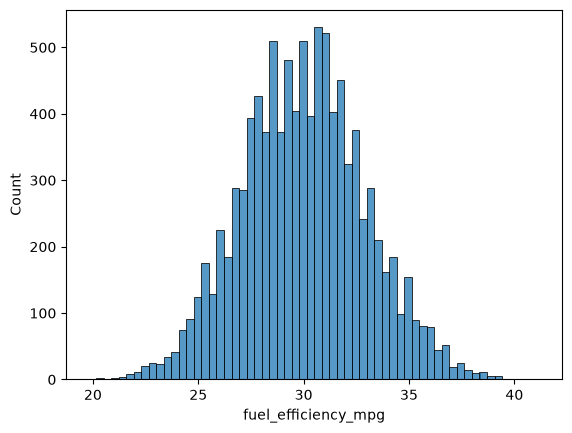

In [15]:
sns.histplot(dataset.fuel_efficiency_mpg)

In [16]:
dataset.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [17]:
dataset.horsepower.median()

np.float64(254.0)

In [18]:
dataset.horsepower.mean()

np.float64(254.44601556505535)

In [19]:
n = len(dataset)
n

10000

In [20]:
n_val = int(len(dataset) * 0.2)
n_test = int(len(dataset) * 0.2)
n_train = int(len(dataset) - n_val - n_test)
n_train, n_val, n_test

(6000, 2000, 2000)

In [21]:
np.random.seed(42)

In [22]:
idx = np.arange(n)

In [23]:
np.random.shuffle(idx)

In [24]:
df_train = dataset.iloc[idx[:n_train]]
df_val = dataset.iloc[idx[n_train:n_train+n_val]]
df_test = dataset.iloc[idx[n_train+n_val:]]

In [25]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [26]:
df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,1900,239.0,3790,2015,32.5
1,2000,224.0,4380,1992,29.1
2,2330,286.0,4090,2022,34.1
3,2300,NaN,4150,1997,30.6
4,2340,269.0,4400,2001,30.7


In [27]:
def linear_regression_train(X,y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    w0 = w_full[0]
    w = w_full[1:]

    return w0, w

In [28]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

In [29]:
y_train

array([32.5, 29.1, 34.1, ..., 27.7, 31.6, 28. ], shape=(6000,))

In [30]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [31]:
df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year
0,1900,239.0,3790,2015
1,2000,224.0,4380,1992
2,2330,286.0,4090,2022
3,2300,NaN,4150,1997
4,2340,269.0,4400,2001


In [32]:
df_train.isnull().sum()

engine_displacement      0
horsepower             538
vehicle_weight           0
model_year               0
dtype: int64

In [46]:
dataset.model_year.max()

np.int64(2024)

In [69]:
def prepare_X_0(df):
    df = df.copy()
        
    df = df.fillna(0)

    X = df.values
    return X

In [70]:
def rmse(y,y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    rmse = np.sqrt(mse)
    return rmse

In [71]:
# Training
X_train = prepare_X(df_train)
w0, w = linear_regression_train(X_train, y_train)

# Validation
X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

rmse(y_val, y_pred)

np.float64(2.205293194751098)

In [72]:
def prepare_X_mean(df):
    df = df.copy()
        
    df = df.fillna(dataset.horsepower.mean())
    
    X = df.values
    return X

In [73]:
# Training
X_train = prepare_X_mean(df_train)
w0, w = linear_regression_train(X_train, y_train)

# Validation
X_val = prepare_X_mean(df_val)
y_pred = w0 + X_val.dot(w)

rmse(y_val, y_pred)

np.float64(2.2018163784483527)

<Axes: ylabel='Count'>

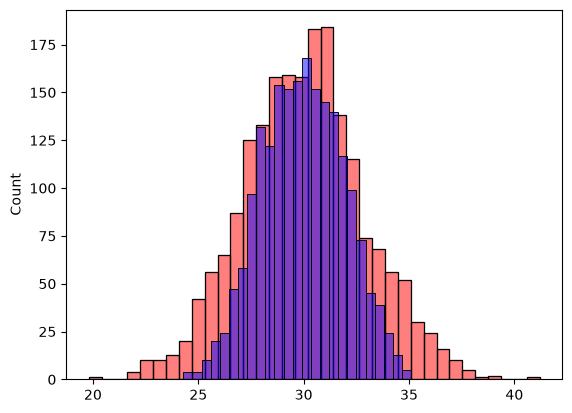

In [74]:
sns.histplot(y_val, color = 'red', alpha = 0.5)
sns.histplot(y_pred, color = 'blue', alpha = 0.5)

In [75]:
def linear_regression_train_reg(X,y,r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r*(np.eye(XTX.shape[0]))
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    w0 = w_full[0]
    w = w_full[1:]

    return w0, w

In [76]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    # Training
    X_train = prepare_X_0(df_train)
    w0, w = linear_regression_train_reg(X_train, y_train,r=r)
    
    # Validation
    X_val = prepare_X_0(df_val)
    y_pred = w0 + X_val.dot(w)
    
    score = round(rmse(y_val, y_pred),4)

    print(r, score)

0 2.2053
0.01 2.2058
0.1 2.2241
1 2.3492
5 2.4094
10 2.4195
100 2.4292


In [90]:
rmse_list = []
for i in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:

    np.random.seed(i)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train_i = dataset.iloc[idx[:n_train]]
    df_val_i = dataset.iloc[idx[n_train:n_train+n_val]]
    df_test_i = dataset.iloc[idx[n_train+n_val:]]

    df_train_i = df_train_i.reset_index(drop=True)
    df_val_i = df_val_i.reset_index(drop=True)
    df_test_i = df_test_i.reset_index(drop=True)

    y_train_i = df_train_i.fuel_efficiency_mpg.values
    y_val_i = df_val_i.fuel_efficiency_mpg.values
    y_test_i = df_test_i.fuel_efficiency_mpg.values

    del df_train_i['fuel_efficiency_mpg']
    del df_val_i['fuel_efficiency_mpg']
    del df_test_i['fuel_efficiency_mpg']

    X_train = prepare_X_0(df_train_i)
    w0, w = linear_regression_train(X_train, y_train_i)
    
    # Validation
    X_val = prepare_X_0(df_val_i)
    y_pred = w0 + X_val.dot(w)
    
    score = round(rmse(y_val_i, y_pred),4)

    rmse_list.append(score)
    
    print(i, score)

0 2.2392
1 2.2021
2 2.1634
3 2.2044
4 2.2019
5 2.2458
6 2.2697
7 2.1908
8 2.2166
9 2.207


In [93]:
round(np.std(rmse_list),3)

np.float64(0.029)

In [95]:
np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train_9_combined = dataset.iloc[idx[:n_train+n_val]]
df_test_9 = dataset.iloc[idx[n_train+n_val:]]

df_train_9_combined = df_train_9_combined.reset_index(drop=True)
df_test_9 = df_test_9.reset_index(drop=True)

y_train_9_combined = df_train_9_combined.fuel_efficiency_mpg.values
y_test_9 = df_test_9.fuel_efficiency_mpg.values

del df_train_9_combined['fuel_efficiency_mpg']
del df_test_9['fuel_efficiency_mpg']

In [98]:
# Training
X_train = prepare_X_0(df_train_9_combined)
w0, w = linear_regression_train_reg(X_train, y_train_9_combined,r=0.001)

# Validation
X_val = prepare_X_0(df_test_9)
y_pred = w0 + X_val.dot(w)

score = round(rmse(y_test_9, y_pred),3)

print(r, score)

100 2.236
